# Measure the Internet with Cloudflare Radar 🌍
**SINF 2026 · FEUP · Cloudflare workshop**

> ✅ **Solutions version.** Try the challenges in `workshop.ipynb` first, then compare with these answers.

Every day, a huge share of the world's websites run through Cloudflare's network.
[Cloudflare Radar](https://radar.cloudflare.com) shares public trends from that traffic.

Today **you** will write Python to answer real questions about the Internet, starting with Portugal.

**Rules of the challenge**
- Work in pairs.
- Each challenge has a goal, a check, and 💡 hints. Open the hints only if you're stuck.
- Use the docs: [Radar API reference](https://developers.cloudflare.com/api/resources/radar/)

______________

### **Part 1: Setup and first test**

**Step 0: Get your Radar API token**

1. Create a free Cloudflare account at [dash.cloudflare.com/sign-up](https://dash.cloudflare.com/sign-up) and **verify your email**
2. Go to **My Profile** → **API Tokens** → **Create Token**
3. Under **Custom token**, click **Get started**
4. Fill in:
   - **Token name:** `sinf-workshop`
   - **Permissions:** `Account` → `Radar` → `Read`
5. Click **Continue to summary** → **Create Token**
6. **Copy the token.** It's shown only once.

**Step 1: Save your token safely**

Click the **key icon** on the left and add a secret:
- **Name:** `RADAR_TOKEN`
- **Value:** your Radar API token
- Turn on **Notebook access**

⚠️ Never paste your token directly in the code.

**Step 2: Load the libraries**

Run the cell below (**Shift + Enter**). It loads everything you need today.

In [ ]:
import requests                    # makes HTTP calls to the Radar API
import pandas as pd                # turns the answers into tables and charts
from google.colab import userdata  # reads the RADAR_TOKEN secret saved in Colab

print("Ready!")

Ready!


**Step 3: Your first request**

**Goal:** in the cell below, ask the Radar API for the **share of mobile vs desktop traffic in the world, over the last 7 days**.

**You got it if** you print something like: `{'desktop': '...', 'mobile': '...', 'other': '...'}`

**Docs that help:**
- [Make your first API request](https://developers.cloudflare.com/radar/get-started/first-request/): a step-by-step example
- [HTTP summary by dimension](https://developers.cloudflare.com/api/resources/radar/subresources/http/methods/summary_v2/): every parameter you can use (`dateRange`, `location`, `botClass`...)

<details><summary>Why you should use <code>requests</code> and not the Cloudflare SDK</summary>

Cloudflare has an official Python library (`pip install cloudflare`) and it's a great choice for real projects as it has autocomplete, types and retries.

Today we use plain `requests` on purpose:
- You see the **real HTTP request**: the URL, the header and the parameters.
- The parameters match the **API docs** one to one.
- `requests` already comes with Colab, so there's nothing to install.
- It works with **any** HTTP API, not just Cloudflare's.

</details>

<details><summary>💡 Hint 1: Where is the data?</summary>

The endpoint is:
`https://api.cloudflare.com/client/v4/radar/http/summary/DEVICE_TYPE`

Docs: [HTTP summary by dimension](https://developers.cloudflare.com/api/resources/radar/subresources/http/methods/summary_v2/)
</details>

<details><summary>💡 Hint 2: How do I read my secret and call the API?</summary>

- Read the token with `userdata.get("RADAR_TOKEN")`.
- Make the request with the `requests` library.
- The API expects a header: `Authorization: Bearer <your token>`
- The time window is a parameter: `dateRange`
</details>

<details><summary>💡 Hint 3: I get a big JSON, where's my answer?</summary>

Look inside `result`, then `summary_0`.
</details>

In [ ]:
# Read the token from the Colab secret (never paste it in the code)
TOKEN = userdata.get("RADAR_TOKEN")

# Endpoint: HTTP traffic summary, split by device type (mobile, desktop, other)
URL = "https://api.cloudflare.com/client/v4/radar/http/summary/DEVICE_TYPE"

# dateRange="7d" asks for the last 7 days
# The token goes in the Authorization header as "Bearer <token>"
r = requests.get(URL, params={"dateRange": "7d"},
                 headers={"Authorization": f"Bearer {TOKEN}"})

# The answer is JSON: the percentages are inside result -> summary_0
print(r.json()["result"]["summary_0"])

{'desktop': '61.033771', 'mobile': '38.936944', 'other': '0.029285'}


### **Build your own helper**

You'll call the API many times today. Let's not copy-paste the same code over and over.

**Goal:** write a function `radar(path, **params)` that:
- takes the part of the URL **after** `/radar/` (for example `"http/summary/DEVICE_TYPE"`)
- takes any filters as keyword arguments (for example `dateRange="7d"`)
- returns only the `result` part of the answer

**You got it if** this gives you the same answer as Part 1:
`radar("http/summary/DEVICE_TYPE", dateRange="7d")["summary_0"]`

<details><summary>💡 Hint 1</summary>

Start from your Part 1 code and turn it into a function. An f-string is useful to build the URL.
</details>

<details><summary>💡 Hint 2</summary>

`requests.get(...)` accepts `params=params`, so you don't need to build the `?a=b&c=d` part yourself.
</details>

<details><summary>💡 Hint 3: Bonus</summary>

Call `r.raise_for_status()` so errors show up clearly instead of failing silently later.
</details>

<details><summary>🆘 <b>Stuck? Use this helper</b></summary>

No problem! Copy this into the cell below, run it, and move on to Part 2. You can come back and understand it later.

```python
TOKEN = userdata.get("RADAR_TOKEN")

def radar(path, **params):
    """Call the Radar API and return the 'result' part."""
    r = requests.get(f"https://api.cloudflare.com/client/v4/radar/{path}",
                     params=params,
                     headers={"Authorization": f"Bearer {TOKEN}"})
    r.raise_for_status()
    return r.json()["result"]
```

</details>

In [ ]:
def radar(path, **params):
    """Call the Radar API and return the 'result' part."""
    # path = the part of the URL after /radar/
    # **params = any filters (dateRange, location...), sent as ?key=value

    r = requests.get(f"https://api.cloudflare.com/client/v4/radar/{path}",
                     params=params,
                     headers={"Authorization": f"Bearer {TOKEN}"})

    # Stop with a clear error if the call failed (bad token, wrong parameter...)
    r.raise_for_status()

    # Keep only the useful part of the answer
    return r.json()["result"]

# Check: same answer as the first request, in one short line
radar("http/summary/DEVICE_TYPE", dateRange="7d")["summary_0"]

{'desktop': '61.033771', 'mobile': '38.936944', 'other': '0.029285'}

## **Part 2: Ask real questions!!**

Now you have your own `radar()` tool. Time to ask real questions!

Each challenge gives you a **question**. You decide how to answer it with data.
There are no wrong answers, only interesting data.

____________

### **Challenge 1: Is Portugal more mobile than the world?**

**Question:** do people in Portugal use their phones more or less than the world average?

**Goal:** compare the share of **mobile vs desktop** traffic for **the world** and **Portugal** over the last 7 days, in a **table** and a **bar chart**.

**You got it if** you have a chart with two bars (World and Portugal) for each device type.

<details><summary>💡 Hint 1: How do I filter by country?</summary>

Look for a parameter called `location` in the docs. It uses 2-letter country codes (Portugal = `PT`).
</details>

<details><summary>💡 Hint 2: How do I make the table?</summary>

`pandas.DataFrame` accepts a dictionary of dictionaries: `{"World": ..., "Portugal": ...}`
</details>

<details><summary>💡 Hint 3: My chart is empty or broken!</summary>

Look closely at the values. Are they numbers or **text**?
`.astype(float)` might help.
</details>

🔍 **Explore:** try other countries (`ES`, `BR`, `IN`, `US`...). Which one is the most mobile?

             World   Portugal
desktop  61.033771  61.689930
mobile   38.936944  38.293728
other     0.029285   0.016342


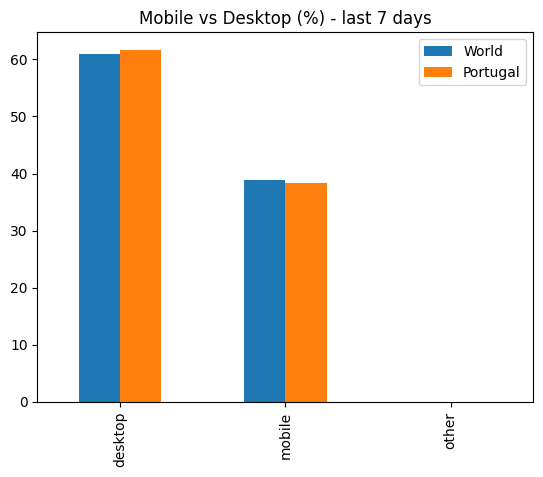

In [ ]:
# 1. Get the data: once for the whole world, once filtered with location="PT"
world    = radar("http/summary/DEVICE_TYPE", dateRange="7d")["summary_0"]
portugal = radar("http/summary/DEVICE_TYPE", dateRange="7d", location="PT")["summary_0"]

# 2. Build the table: one column per area, one row per device type
# The API sends the values as text ("61.3"), so .astype(float) turns them into numbers
df = pd.DataFrame({"World": world, "Portugal": portugal}).astype(float)
print(df)

# 3. Bar chart: World and Portugal side by side for each device type
df.plot(kind="bar", title="Mobile vs Desktop (%) - last 7 days");

**Look at your result.** Is mobile above or below 50%?

Most people browse on their phones... does your number feel right?

<details><summary>👉 <b>Click here once you've discussed it with your pair</b></summary>

<br>

### Challenge 1b: Who is really browsing? 🤖 vs 🧑

Not all Internet traffic comes from humans. A lot of it comes from **bots** like crawlers, scripts, monitoring tools...

**Question:** what happens to Challenge 1 if you count **humans only**?

**Before you code, guess:** will mobile go up or down?

**Goal:** repeat Challenge 1 with human traffic only.

**You got it if** your numbers change compared to Challenge 1.

<details><summary>💡 Hint 1</summary>

Search the docs for a parameter related to **bots**.

</details>

<details><summary>💡 Hint 2</summary>

The parameter is `botClass`. Which value means "human"?
[Bot classes](https://developers.cloudflare.com/radar/concepts/bot-classes/)

</details>

</details>

             World   Portugal
mobile   54.166513  44.519678
desktop  45.812606  55.462818
other     0.020881   0.017504


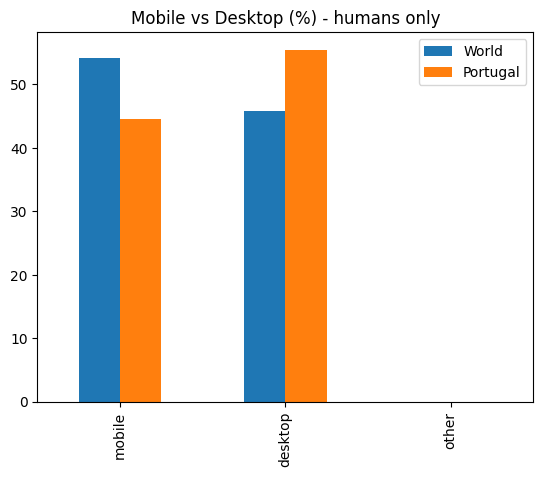

In [ ]:
# Same as Challenge 1, plus botClass="LIKELY_HUMAN" to keep human traffic only (no bots)
world    = radar("http/summary/DEVICE_TYPE", dateRange="7d", botClass="LIKELY_HUMAN")["summary_0"]
portugal = radar("http/summary/DEVICE_TYPE", dateRange="7d", botClass="LIKELY_HUMAN", location="PT")["summary_0"]

# Same table and chart as before, so the two results are easy to compare
df = pd.DataFrame({"World": world, "Portugal": portugal}).astype(float)
print(df)
df.plot(kind="bar", title="Mobile vs Desktop (%) - humans only");

### What just happened?

Most bots identify as **desktop**. So when bots are included, mobile looks smaller than it really is.

**Lesson:** before you trust a number, ask *what exactly is being counted*.
The same question can give a different answer depending on how you filter the data.

**Discuss with your pair:**
- Did Portugal's position compared with the world change?
- Why might Portugal be less (or more) mobile than the world? Test your idea with another country.

### **Challenge 2: The day Portugal went dark 🔌**

Something big happened to Portugal's Internet traffic in **April 2025**.

**Question:** can you find **what day** and **what time** it happened, just by looking at the data?

**Goal:** plot Portugal's **human** Internet traffic, **hour by hour**, for the **whole month of April 2025**.

**You got it if** you see a line chart with daily waves and **one day that looks very different**.

<details><summary>💡 Hint 1: Which data?</summary>

You need traffic **over time**, not a summary. Look in the docs for an HTTP **timeseries** endpoint.

</details>

<details><summary>💡 Hint 2: How do I choose the dates?</summary>

Instead of `dateRange`, use `dateStart` and `dateEnd`.
They use this format: `2025-04-01T00:00:00Z`

To get one point per hour, look for a parameter called `aggInterval`.

</details>

<details><summary>💡 Hint 3: Where are the numbers?</summary>

Inside `result` → `serie_0` you'll find two lists: `timestamps` and `values`.
`pd.to_datetime(...)` turns the timestamps into real dates for your chart.

</details>

<details><summary>💡 Hint 4: The times look wrong!</summary>

The API uses **UTC** time. Try `.tz_convert("Europe/Lisbon")` on your index. 🕐

</details>

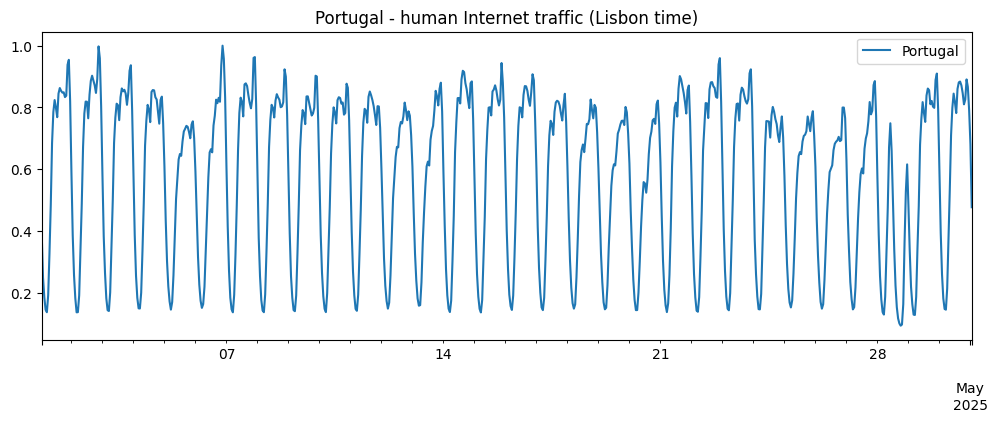

In [ ]:
# http/timeseries = traffic over time (not a single summary)
data = radar("http/timeseries",
             location="PT",                       # Portugal only
             dateStart="2025-04-01T00:00:00Z",    # start of April 2025 (UTC)
             dateEnd="2025-05-01T00:00:00Z",      # end of April 2025 (UTC)
             aggInterval="1h",                    # one point per hour
             botClass="LIKELY_HUMAN")["serie_0"]  # humans only; serie_0 holds timestamps + values

# Build a table: timestamps as the index (rows), traffic as the values
df = pd.DataFrame({"Portugal": data["values"]},
                  index=pd.to_datetime(data["timestamps"])).astype(float)

# The API answers in UTC: convert to Portugal's local time
df.index = df.index.tz_convert("Europe/Lisbon")

# Line chart: a wave every day, and one day (28 April) that looks very different
df.plot(title="Portugal - human Internet traffic (Lisbon time)", figsize=(12, 4));

🔍 **Explore:**
- At what **time** did the drop start?

                           Portugal
2025-04-28 09:00:00+01:00  0.732720
2025-04-28 09:15:00+01:00  0.807932
2025-04-28 09:30:00+01:00  0.868272
2025-04-28 09:45:00+01:00  0.884561
2025-04-28 10:00:00+01:00  0.873229
2025-04-28 10:15:00+01:00  0.915014
2025-04-28 10:30:00+01:00  0.920113
2025-04-28 10:45:00+01:00  0.964731
2025-04-28 11:00:00+01:00  1.000000
2025-04-28 11:15:00+01:00  0.981303
2025-04-28 11:30:00+01:00  0.516006
2025-04-28 11:45:00+01:00  0.735127
2025-04-28 12:00:00+01:00  0.701841
2025-04-28 12:15:00+01:00  0.654816
2025-04-28 12:30:00+01:00  0.571671
2025-04-28 12:45:00+01:00  0.552125
2025-04-28 13:00:00+01:00  0.487394
2025-04-28 13:15:00+01:00  0.447450
2025-04-28 13:30:00+01:00  0.388244
2025-04-28 13:45:00+01:00  0.348725
2025-04-28 14:00:00+01:00  0.316572
2025-04-28 14:15:00+01:00  0.279887
2025-04-28 14:30:00+01:00  0.260198
2025-04-28 14:45:00+01:00  0.237960
2025-04-28 15:00:00+01:00  0.209490


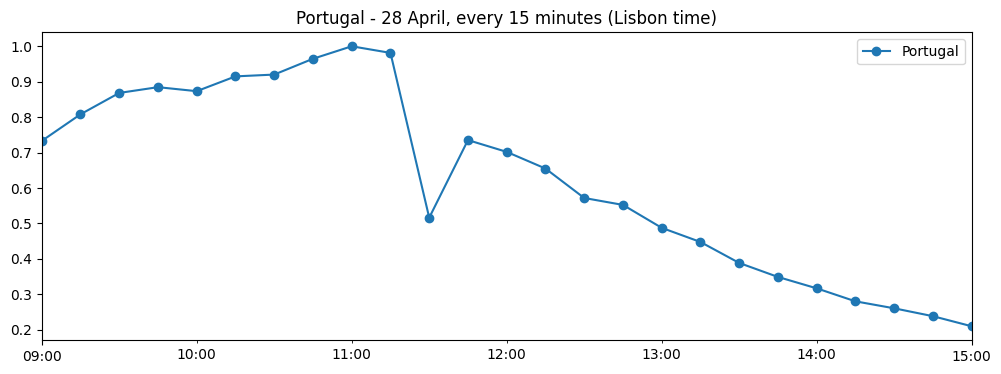

In [ ]:
# 1. At what time did the drop start?
# Zoom in on 28 April, 08:00-14:00 UTC, with one point every 15 minutes
zoom = radar("http/timeseries",
             location="PT",
             dateStart="2025-04-28T08:00:00Z",
             dateEnd="2025-04-28T14:00:00Z",
             aggInterval="15m",                   # finer detail than 1h
             botClass="LIKELY_HUMAN")["serie_0"]

# Same steps as before: build the table and switch to Lisbon time
pt = pd.DataFrame({"Portugal": zoom["values"]},
                  index=pd.to_datetime(zoom["timestamps"])).astype(float)
pt.index = pt.index.tz_convert("Europe/Lisbon")

# Print the numbers to spot the 15 minutes where traffic fell
print(pt)

# marker="o" draws a dot for each 15-minute point
pt.plot(title="Portugal - 28 April, every 15 minutes (Lisbon time)", figsize=(12, 4), marker="o");

### 📉 What does the data tell us?

**What do the numbers mean?** Traffic is scaled from **0 to 1** and 1.0 is the busiest moment in the time window we asked for. These are not request counts, they show the **shape** of the traffic.

**What happened:**
- Between **11:15 and 11:30**, traffic fell from 0.98 to 0.52. **Half of Portugal's Internet traffic vanished in 15 minutes.**
- At **11:45**, there was a small bounce.
- Then traffic kept falling slowly, down to **about one fifth** of the peak by 15:00.

**Discuss:** why the small bounce, and why the slow decline instead of a sudden drop to zero?
Think about phone batteries, Wi-Fi routers, and mobile towers running on backup power.

🔍 **Explore:**
- How long did it take to come back to normal?

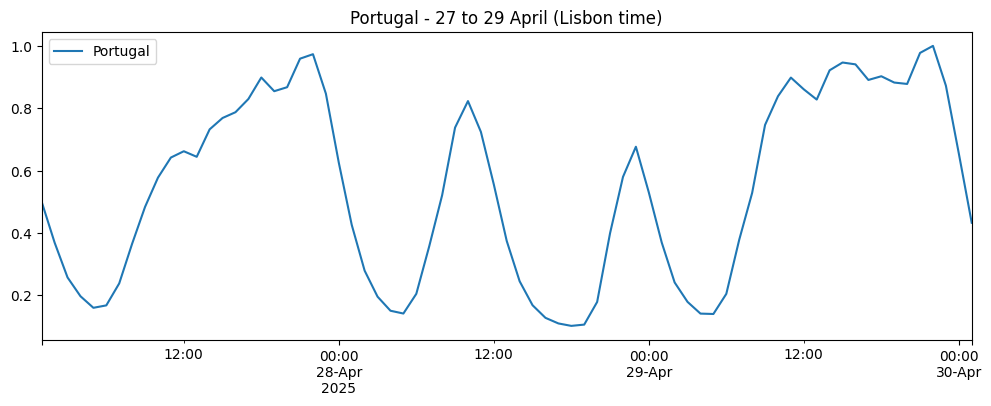

In [ ]:
# 2. How long did it take to come back to normal?
# Look at 3 days: 27 April (normal), 28 April (blackout), 29 April (day after)
week = radar("http/timeseries",
             location="PT",
             dateStart="2025-04-27T00:00:00Z",
             dateEnd="2025-04-30T00:00:00Z",
             aggInterval="1h",
             botClass="LIKELY_HUMAN")["serie_0"]

pt3 = pd.DataFrame({"Portugal": week["values"]},
                   index=pd.to_datetime(week["timestamps"])).astype(float)
pt3.index = pt3.index.tz_convert("Europe/Lisbon")

# Compare the 28th with the normal days before and after
pt3.plot(title="Portugal - 27 to 29 April (Lisbon time)", figsize=(12, 4));

### How long did it take to come back?

Compare **27 April** (a normal day) with the **28th** and the **29th**:

- **28 April, 11:30 to ~19h:** traffic stays very low, as low as a normal 5am.
- **From ~19–20h:** traffic starts coming back as power is restored, region by region.
- **Around midnight:** a peak, as people get back online, charge their phones and check the news.
- **29 April:** the day looks **just like the 27th**. Back to normal.

**Answer:** about **8–9 hours** before traffic started to recover, and **back to normal by the next morning**.

🔍 **Explore:**
- Try `ES`. Did Spain look the same?

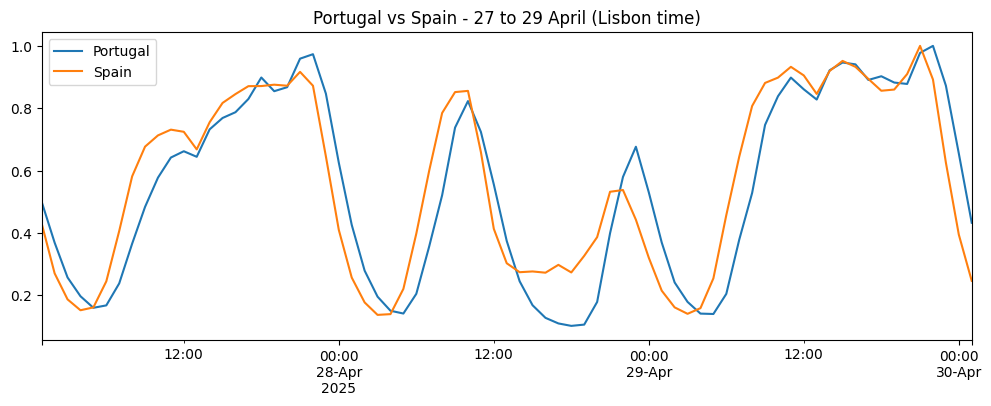

In [ ]:
# 3. Did Spain look the same?
# Same request as for Portugal, only location="ES" changes
es = radar("http/timeseries",
           location="ES",
           dateStart="2025-04-27T00:00:00Z",
           dateEnd="2025-04-30T00:00:00Z",
           aggInterval="1h",
           botClass="LIKELY_HUMAN")["serie_0"]

# Add Spain as a second column of the Portugal table (pt3, from the cell above)
# Convert to Lisbon time too, so both lines use the same clock
pt3["Spain"] = pd.Series(es["values"],
                         index=pd.to_datetime(es["timestamps"]).tz_convert("Europe/Lisbon")).astype(float)

# One chart, two lines: when did each country drop and come back?
pt3.plot(title="Portugal vs Spain - 27 to 29 April (Lisbon time)", figsize=(12, 4));

### 🇵🇹 vs 🇪🇸 Did Spain look the same?

**Similar, but not the same:**
- ⏱️ Both dropped **at the same moment**: one blackout for the whole Iberian Peninsula.
- Spain didn't fall as low: about **a quarter** of its peak, while Portugal fell to about **a tenth**.
- Spain started recovering **earlier and slowly**. Portugal stayed dark **longer**, then came back **faster**.

⚠️ **One trap in this chart:**
1. Spain looks **one hour early** every day. Why? (Hint: what time zone is the chart in?)